# Co-movement rules: mining, testing and the unusual days

**DSAI4102 Applied Data Mining · Notebook 2 of 3** (run after `stocks.ipynb`, before `events.ipynb`)
Farid Abdul Rehman · Muzayyan Parkar · Mohamad Zain

**Co-movement** is the tendency of some stocks to make big moves together: chip makers with chip makers, banks with
banks. This notebook turns daily prices of the S&P 100 into "baskets" of big moves and mines **association rules**
such as `{AMAT_UP} -> {LRCX_UP}` ("when Applied Materials makes a big up move, Lam Research usually does too").
It answers the baseline question the event analysis depends on:

**Q0. Are the mined rules real co-movement, or just the market moving?** (Sections 3-4)

and builds three things `events.ipynb` uses or extends:

* how co-movement inside and between sectors, and with the semiconductor stocks, changes over time (Section 5);
* which mined rules last: the prediction task (Section 6);
* the unusual days, found without labels by an Isolation Forest (Section 7).

Reads `data/prices.csv` and `data/stocks.csv` (from `stocks.ipynb`); writes every figure and table to
`outputs/rules/`, and every quoted number to `outputs/rules/key_numbers.json`.
The code was written with the help of an AI assistant (Claude, Anthropic) and reviewed by the group.

## 1. Settings

Everything that can change a result lives in this cell.

In [1]:
from pathlib import Path
from math import comb
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
from scipy.stats import hypergeom, spearmanr
from sklearn.ensemble import IsolationForest, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- data -------------------------------------------------------------------
OUT_DIR = Path("outputs/rules")
OUT_DIR.mkdir(parents=True, exist_ok=True)
MARKET = "SPY"                     # S&P 500 ETF, our stand-in for "the market"
STUDY_START = "2016-01-01"         # first basket; 2014-2015 is only used to estimate betas and volatility

# ---- what counts as a "major move" -------------------------------------------
RETURN_MODES = ["raw", "excess", "residual"]
MAIN_MODE = "residual"             # raw = own return; excess = minus SPY; residual = minus beta x SPY (market model)
BETA_WINDOW = 252                  # trading days used to estimate each stock's beta (about one year)
VOL_WINDOW = 60                    # trading days used to measure "typical" move size
Z_K = 1.0                          # a move is major when |return| >= Z_K x typical move size

# ---- mining -------------------------------------------------------------------
WINDOW = 252                       # one rolling window = one year of trading days = 252 baskets
STEP = 21                          # move the window forward one month (21 trading days) at a time
MIN_SUPPORT = 0.04                 # itemset on at least 4% of the window's days (about 10 days)
MIN_CONFIDENCE = 0.40
MIN_LIFT = 1.5
MAX_LEN = 3                        # rules with at most 3 items (main, residual mode)
COMPARE_MAX_LEN = 2                # the raw / excess / residual comparison uses pair rules: with 100 stocks, raw
                                   # crash windows would give millions of 3-item rules
N_SHUFFLES = 3                     # shuffled copies per window for the chance test
FDR_Q = 0.05                       # false discovery rate for the Fisher exact test

# ---- co-movement over time and rule survival ------------------------------------
SPLIT = pd.Timestamp("2022-12-01") # periods compared in Section 5, and the train/test split in Section 6
FUTURE_DAYS = 126                  # a rule "survives" if it is mined again from the next 126 baskets (half a year)
SEED = 42

stocks = pd.read_csv("data/stocks.csv")
TICKERS = stocks["ticker"].tolist()
GROUP_OF = dict(zip(stocks["ticker"], stocks["sector"]))          # "group" = GICS sector
SECTORS = stocks["sector"].value_counts().index.tolist()
SEMIS = stocks.loc[stocks["semiconductor"], "ticker"].tolist()
print(f"{len(TICKERS)} stocks, {len(SECTORS)} sectors, {len(SEMIS)} semiconductor stocks: {SEMIS}")

100 stocks, 11 sectors, 9 semiconductor stocks: ['AMAT', 'AMD', 'AVGO', 'INTC', 'LRCX', 'MU', 'NVDA', 'QCOM', 'TXN']


In [2]:
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SECTOR_COLORS = dict(zip(SECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#7a4fc9", "#b3261e", "#d4a106",
                                   "#0f8b8d", "#898781", "#c2569b", "#5b8c2a", "#3b3b3b"]))
MODE_COLORS = {"raw": "#b3261e", "excess": "#eb6834", "residual": "#2a78d6"}
HIGHLIGHT = "#b3261e"
LIFT_CMAP = LinearSegmentedColormap.from_list("lift", ["#184f95", "#6da7ec", "#f0efec", "#ec8a7c", "#b3261e"])
LIFT_CMAP.set_bad(SURFACE)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})
KEY = {}   # every number quoted in the slides is stored here and written to key_numbers.json


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

## 2. Data

Adjusted closing prices of the S&P 100 and SPY from `stocks.ipynb`. Companies that listed after mid-2014 have no
prices before their first trading day; they make no moves until they have enough history (Section 3).

In [3]:
prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True).sort_index()[TICKERS + [MARKET]]
print(f"{prices.shape[0]} trading days x {len(TICKERS)} stocks + {MARKET}, {prices.index[0].date()} to {prices.index[-1].date()}")
KEY["data"] = {"days_total": int(prices.shape[0]), "first_day": str(prices.index[0].date()),
               "last_day": str(prices.index[-1].date()), "n_stocks": len(TICKERS), "n_sectors": len(SECTORS)}

3134 trading days x 100 stocks + SPY, 2014-06-02 to 2026-11-13


## 3. Preprocessing: from prices to baskets

1. **Daily returns** from adjusted closes.
2. **Remove the market**, three ways, so the effect of the choice can be measured:
   - `raw`: the stock's own return.
   - `excess`: stock return minus SPY's return.
   - `residual` (main setting): stock return minus *beta* × SPY's return. Beta is how strongly the stock usually
     follows the market, estimated on the previous 252 days only (the market model of event studies). A stock with
     beta 1.5 "normally" falls 3% when SPY falls 2%; only the part beyond that counts as its own move.
3. **Major move.** Divide each residual by the stock's typical residual size over the previous 60 days (a
   z-score). `z >= 1` gives the item `NVDA_UP`, `z <= -1` gives `NVDA_DOWN`. Using each stock's own volatility
   judges a quiet stock like KO and a jumpy one like TSLA fairly. Beta and volatility are shifted by one day, so
   nothing from "today" or the future decides what today's move is. A stock needs 252 + 60 days of prices before it
   can make a move, which is how late-listed companies enter.
4. **Basket** = one trading day; its items are the stocks that made a major move that day.

In [4]:
def market_model_residuals(returns, market, window):
    # Return (residual returns, betas). Beta for day t uses days t-window .. t-1 only.
    betas = pd.DataFrame({t: returns[t].rolling(window).cov(market) / market.rolling(window).var()
                          for t in returns.columns}).shift(1)
    residuals = returns - betas.mul(market, axis=0)
    return residuals, betas


def find_major_moves(returns, z_k, vol_window):
    # Turn returns into True/False items: one <TICKER>_UP and one <TICKER>_DOWN column per stock.
    typical_move = returns.rolling(vol_window).std().shift(1)       # known before today
    score = returns / typical_move
    up, down = score >= z_k, score <= -z_k
    up.columns = [f"{t}_UP" for t in returns.columns]
    down.columns = [f"{t}_DOWN" for t in returns.columns]
    return pd.concat([up, down], axis=1), score


all_returns = prices.pct_change(fill_method=None)
stock_returns, market_returns = all_returns[TICKERS], all_returns[MARKET]
residual_returns, betas = market_model_residuals(stock_returns, market_returns, BETA_WINDOW)
returns_by_mode = {"raw": stock_returns, "excess": stock_returns.sub(market_returns, axis=0), "residual": residual_returns}
items_by_mode, zscores_by_mode = {}, {}
for mode, rets in returns_by_mode.items():
    its, z = find_major_moves(rets, Z_K, VOL_WINDOW)
    items_by_mode[mode] = its.loc[STUDY_START:]
    zscores_by_mode[mode] = z.loc[STUDY_START:]

items = items_by_mode[MAIN_MODE]
zscores = zscores_by_mode[MAIN_MODE]
DAYS = items.index
active = zscores.notna()                                            # stock has enough history on that day
print(f"{len(items)} baskets from {DAYS[0].date()} to {DAYS[-1].date()}, {items.shape[1]} possible items")
print(f"Stocks with enough history: {active.iloc[0].sum()} on the first day, {active.iloc[-1].sum()} on the last day")
for day, row in items.tail(2).iterrows():
    print(day.date(), "->", sorted(row.index[row]))

2733 baskets from 2016-01-04 to 2026-11-13, 200 possible items
Stocks with enough history: 95 on the first day, 100 on the last day
2026-11-12 -> ['ABT_DOWN', 'AMD_UP', 'ANET_UP', 'AVGO_UP', 'AXP_DOWN', 'CSCO_UP', 'GE_DOWN', 'GM_DOWN', 'GOOGL_UP', 'NFLX_DOWN', 'NVDA_DOWN', 'PFE_DOWN', 'SBUX_DOWN', 'SO_DOWN', 'TMO_DOWN', 'TSLA_UP', 'UBER_DOWN']
2026-11-13 -> ['AMD_DOWN', 'ANET_DOWN', 'AVGO_DOWN', 'BAC_UP', 'BMY_UP', 'CSCO_DOWN', 'DELL_DOWN', 'DUK_UP', 'FDX_UP', 'JPM_UP', 'KO_UP', 'MA_UP', 'MDT_UP', 'META_UP', 'MS_UP', 'PEP_UP', 'SCHW_UP', 'SO_UP', 'TXN_DOWN', 'UPS_UP', 'V_UP']


In [5]:
# Basket statistics per return mode. Under 'raw', big market days make huge baskets; removing the market shrinks them.
stats = pd.DataFrame({
    mode: {
        "items per day (mean)": its.sum(axis=1).mean(),
        "items per day (99th pct)": its.sum(axis=1).quantile(0.99),
        "days with 50+ items": int((its.sum(axis=1) >= 50).sum()),
        "share of days with no items": (its.sum(axis=1) == 0).mean(),
    } for mode, its in items_by_mode.items()
}).T
KEY["baskets"] = stats.round(3).to_dict(orient="index")
stats.round(2)

,items per day (mean),items per day (99th pct),days with 50+ items,share of days with no items
raw,25.21,83.00,249.0,0.0
excess,24.28,63.00,113.0,0.0
residual,23.76,61.68,81.0,0.0


## 4. Mining rules on rolling one-year windows

One rule set per **rolling window** of 252 baskets, moved forward 21 trading days at a time (about 120 rule sets),
so a change can be dated.

**Thresholds.** `MIN_SUPPORT = 0.04` (the itemset appears on about 10 of the 252 days), `MIN_CONFIDENCE = 0.4`,
`MIN_LIFT = 1.5` (at least 50% more often than chance), at most 3 items. Section 4.3 measures how many rules chance
alone would produce.

**Why FP-Growth.** It returns exactly the same frequent itemsets as Apriori (checked in 4.2). Apriori generates
candidates level by level and scans the data for each level; FP-Growth compresses the baskets into a tree once.

In [6]:
def ticker_of(item):
    return item.rsplit("_", 1)[0]


def mine_rules(basket, min_support=MIN_SUPPORT, min_confidence=MIN_CONFIDENCE, min_lift=MIN_LIFT,
               max_len=MAX_LEN, algorithm="fpgrowth"):
    # Mine one basket table (rows = days, columns = items). Returns a DataFrame with one row per rule.
    miner = fpgrowth if algorithm == "fpgrowth" else apriori
    itemsets = miner(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    if len(itemsets) == 0:
        return pd.DataFrame()
    rules = association_rules(itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=min_confidence)
    rules = rules[rules["lift"] >= min_lift].copy()
    if rules.empty:
        return pd.DataFrame()
    rules["antecedent"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    rules["consequent"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
    rules["rule"] = rules["antecedent"] + " -> " + rules["consequent"]
    all_items = [frozenset(a) | frozenset(c) for a, c in zip(rules["antecedents"], rules["consequents"])]
    groups = [{GROUP_OF[ticker_of(i)] for i in s} for s in all_items]
    rules["n_items"] = [len(s) for s in all_items]
    rules["n_groups"] = [len(g) for g in groups]
    rules["cross_group"] = rules["n_groups"] > 1
    rules["has_ai"] = [any(ticker_of(i) in SEMIS for i in s) for s in all_items]
    directions = [{i.rsplit("_", 1)[1] for i in s} for s in all_items]
    rules["direction"] = [d.pop() if len(d) == 1 else "MIXED" for d in directions]
    keep = ["rule", "antecedent", "consequent", "antecedents", "consequents", "support", "confidence", "lift",
            "leverage", "conviction", "antecedent support", "consequent support",
            "n_items", "n_groups", "cross_group", "has_ai", "direction"]
    return rules[keep].sort_values(["lift", "rule"], ascending=[False, True]).reset_index(drop=True)


def window_ends(n_days, window=WINDOW, step=STEP):
    # Positions (row numbers) of the last day of each rolling window. The last window always ends on the last day.
    ends = list(range(window - 1, n_days, step))
    if ends[-1] != n_days - 1:
        ends.append(n_days - 1)
    return ends


END_POS = window_ends(len(items))
END_DATES = DAYS[END_POS]
print(f"{len(END_POS)} rolling windows, first ends {END_DATES[0].date()}, last ends {END_DATES[-1].date()}")

120 rolling windows, first ends 2016-12-30, last ends 2026-11-13


In [7]:
# 4.1 Mine every window. Main rule sets: residual moves, up to 3 items. Comparison of the three return definitions:
# pair rules (up to 2 items) for all modes, so the raw crash windows stay computable.
spy_vol = market_returns.loc[STUDY_START:].rolling(WINDOW).std() * np.sqrt(252)   # annualised SPY volatility
window_summary, rules_by_window = [], {}
start = time.time()
for end in END_POS:
    rules = mine_rules(items.iloc[end - WINDOW + 1:end + 1])
    rules_by_window[DAYS[end]] = rules
print(f"Main residual rule sets mined in {time.time() - start:.0f} s, median {np.median([len(r) for r in rules_by_window.values()]):.0f} rules per window")
start = time.time()
for mode in RETURN_MODES:
    its = items_by_mode[mode]
    for end in END_POS:
        basket = its.iloc[end - WINDOW + 1:end + 1]
        rules = mine_rules(basket, max_len=COMPARE_MAX_LEN)
        window_summary.append({
            "mode": mode, "end": DAYS[end], "rules": len(rules),
            "cross_sector_share": rules["cross_group"].mean() if len(rules) else np.nan,
            "items_per_day": basket.sum(axis=1).mean(), "spy_vol": spy_vol.loc[DAYS[end]],
        })
window_summary = pd.DataFrame(window_summary)
print(f"Mode comparison mined in {time.time() - start:.0f} s")
window_summary.to_csv(OUT_DIR / "window_summary.csv", index=False)

# How strongly does the number of rules follow market volatility under each mode? (Spearman rank correlation)
vol_link = {m: spearmanr(g["rules"], g["spy_vol"]).statistic for m, g in window_summary.groupby("mode")}
rule_counts = window_summary.pivot(index="end", columns="mode", values="rules")
main_counts = pd.Series({d: len(r) for d, r in rules_by_window.items()})
KEY["rolling"] = {
    "n_windows": len(END_POS),
    "pair_rules_median": rule_counts.median().round(0).to_dict(),
    "pair_rules_max": rule_counts.max().to_dict(),
    "spearman_rules_vs_spy_vol": {m: round(v, 2) for m, v in vol_link.items()},
    "main_rules_median": float(main_counts.median()), "main_rules_max": int(main_counts.max()),
}
print("Spearman correlation between rule count and SPY volatility:", {m: round(v, 2) for m, v in vol_link.items()})
rule_counts.describe().round(0)

Main residual rule sets mined in 10 s, median 899 rules per window


Mode comparison mined in 74 s
Spearman correlation between rule count and SPY volatility: {'excess': np.float64(0.49), 'raw': np.float64(0.74), 'residual': np.float64(0.42)}


mode,excess,raw,residual
count,120.0,120.0,120.0
mean,879.0,3682.0,459.0
std,433.0,3076.0,174.0
min,259.0,837.0,228.0
25%,563.0,1432.0,315.0
50%,779.0,2461.0,421.0
75%,1161.0,4998.0,558.0
max,2085.0,11842.0,945.0


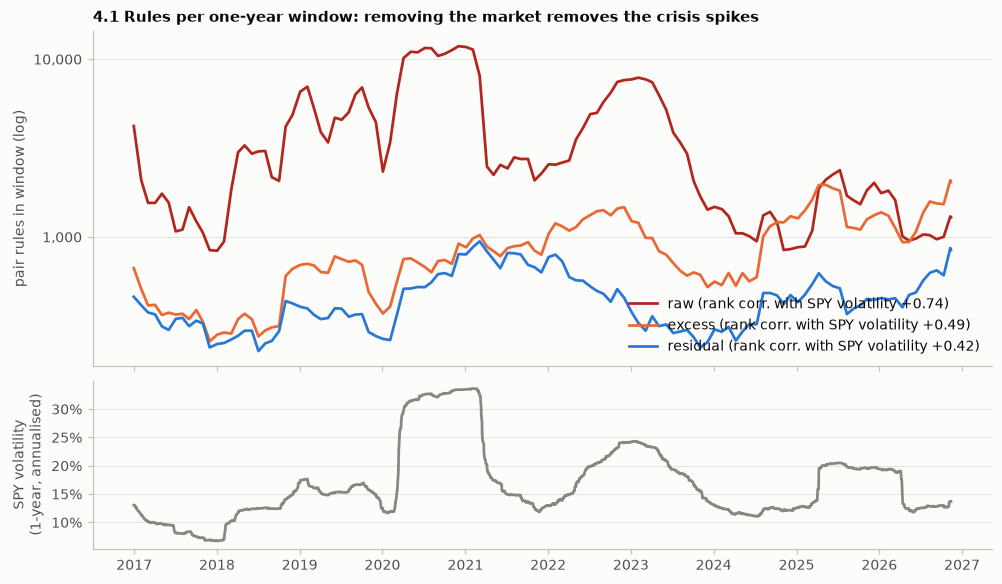

In [8]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, layout="constrained",
                              gridspec_kw={"height_ratios": [2, 1]})
for mode in RETURN_MODES:
    ax.plot(rule_counts.index, rule_counts[mode], color=MODE_COLORS[mode],
            label=f"{mode} (rank corr. with SPY volatility {vol_link[mode]:+.2f})")
ax.set_yscale("symlog", linthresh=10)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("pair rules in window (log)")
ax.grid(axis="y")
ax.legend(frameon=False, loc="lower right")
ax.set_title("4.1 Rules per one-year window: removing the market removes the crisis spikes")
ax2.plot(spy_vol.loc[END_DATES[0]:].index, spy_vol.loc[END_DATES[0]:], color=MUTED)
ax2.set_ylabel("SPY volatility\n(1-year, annualised)")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.grid(axis="y")
year_axis(ax2)
save(fig, "4_1_rules_per_window_by_mode")
plt.show()

**Reading 4.1.** Under `raw` returns the rule count is mostly a picture of market volatility: it spikes when
everything falls together. Under `residual` returns the spikes shrink and the count follows volatility less. Rules
on raw returns largely "rediscover the market".

In [9]:
# 4.2 FP-Growth and Apriori must find exactly the same itemsets. Check and time both on the busiest residual window,
# with rules of up to 2, 3 and 4 items.
busiest = main_counts.idxmax()
end = DAYS.get_loc(busiest)
basket = items.iloc[end - WINDOW + 1:end + 1]
speed = []
for max_len in [2, 3, 4]:
    timings, found = {}, {}
    for algorithm, miner in [("fpgrowth", fpgrowth), ("apriori", apriori)]:
        t0 = time.perf_counter()
        sets = miner(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=max_len)
        timings[algorithm] = time.perf_counter() - t0
        found[algorithm] = set(sets["itemsets"])
    speed.append({"setting": f"residual, up to {max_len} items", "window_end": str(busiest.date()),
                  "itemsets": len(found["fpgrowth"]), "identical": found["fpgrowth"] == found["apriori"],
                  "fpgrowth_s": round(timings["fpgrowth"], 3), "apriori_s": round(timings["apriori"], 3)})
speed = pd.DataFrame(speed).set_index("setting")
KEY["fp_vs_apriori"] = speed.to_dict(orient="index")
speed

,window_end,itemsets,identical,fpgrowth_s,apriori_s
setting,,,,,
"residual, up to 2 items",2026-11-10,2035,True,0.091,0.021
"residual, up to 3 items",2026-11-10,2739,True,0.095,0.044
"residual, up to 4 items",2026-11-10,2872,True,0.096,0.048


### 4.3 Are the rules real, or what chance would produce?

With 200 items there are millions of possible rules, so some will pass the thresholds by luck. Two checks:

- **Shuffle test.** Shuffle each item column on its own. Each stock keeps its number of UP and DOWN days, but any
  link between stocks is destroyed. Rules found in shuffled baskets are what chance alone produces.
- **Fisher exact test with false discovery rate control.** For each rule, a one-sided Fisher exact test asks whether
  antecedent and consequent occur together more often than if they were independent. The Benjamini-Hochberg
  procedure keeps the rules that stay significant when we count **every rule the miner could have returned** (all
  rules of 2 or 3 items from the stocks), not only the ones that passed the thresholds.

In [10]:
def shuffle_items(basket, rng):
    # Shuffle each item column on its own: item supports stay the same, links between items are destroyed.
    return pd.DataFrame({c: rng.permutation(basket[c].to_numpy()) for c in basket.columns}, index=basket.index)


def rule_p_values(rules, n_days):
    # One-sided Fisher exact test (hypergeometric tail) for "antecedent and consequent co-occur more than by chance".
    n_a = np.rint(rules["antecedent support"] * n_days).astype(int)
    n_c = np.rint(rules["consequent support"] * n_days).astype(int)
    n_ac = np.rint(rules["support"] * n_days).astype(int)
    return hypergeom.sf(n_ac - 1, n_days, n_a, n_c)


def benjamini_hochberg(p_values, q, n_tests=None):
    # True for every p-value that survives the Benjamini-Hochberg false discovery rate procedure at level q.
    p = np.asarray(p_values)
    m = len(p) if n_tests is None else n_tests
    order = np.argsort(p)
    thresholds = q * np.arange(1, len(p) + 1) / m
    passed = p[order] <= thresholds
    keep = np.zeros(len(p), dtype=bool)
    if passed.any():
        keep[order[:np.max(np.nonzero(passed)) + 1]] = True
    return keep


# pairs: C(N,2) stock pairs x 4 direction combinations x 2 orientations;
# triples: C(N,3) x 8 direction combinations x 6 ways to split into antecedent -> consequent.
N_POSSIBLE_RULES = comb(len(TICKERS), 2) * 4 * 2 + comb(len(TICKERS), 3) * 8 * 6
print(f"Possible rules with at most {MAX_LEN} items: {N_POSSIBLE_RULES:,}")

rng = np.random.default_rng(SEED)
chance = []
for end_date, rules in rules_by_window.items():
    end = DAYS.get_loc(end_date)
    basket = items.iloc[end - WINDOW + 1:end + 1]
    shuffled_counts = [len(mine_rules(shuffle_items(basket, rng))) for _ in range(N_SHUFFLES)]
    if len(rules):
        rules["p_value"] = rule_p_values(rules, WINDOW)
        rules["significant"] = benjamini_hochberg(rules["p_value"], FDR_Q, n_tests=N_POSSIBLE_RULES)
    chance.append({"end": end_date, "real": len(rules), "shuffled": np.mean(shuffled_counts),
                   "significant": int(rules["significant"].sum()) if len(rules) else 0})
chance = pd.DataFrame(chance).set_index("end")
chance.to_csv(OUT_DIR / "chance_test.csv")
KEY["chance"] = {"n_possible_rules": N_POSSIBLE_RULES,
    "real_rules_total": int(chance["real"].sum()), "shuffled_rules_total": round(float(chance["shuffled"].sum()), 1),
    "chance_ratio_overall": round(float(chance["shuffled"].sum() / chance["real"].sum()), 4),
    "significant_share": round(float(chance["significant"].sum() / chance["real"].sum()), 3),
}
print(KEY["chance"])

Possible rules with at most 3 items: 7,801,200


{'n_possible_rules': 7801200, 'real_rules_total': 131594, 'shuffled_rules_total': 337.3, 'chance_ratio_overall': 0.0026, 'significant_share': 0.765}


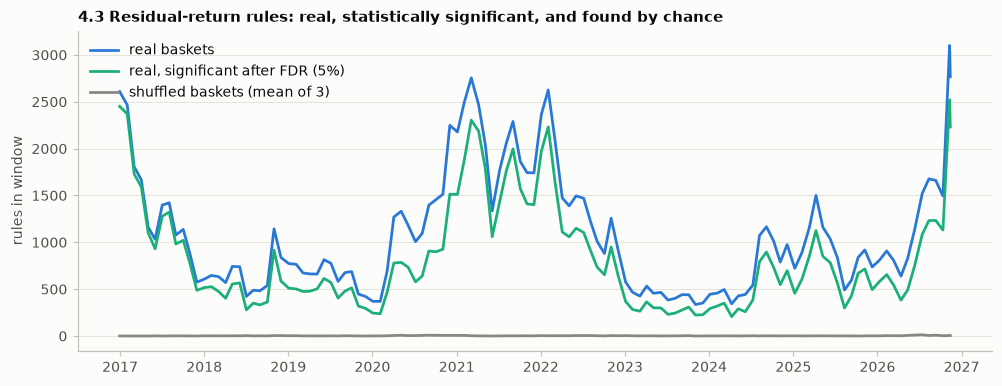

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.plot(chance.index, chance["real"], color=MODE_COLORS["residual"], label="real baskets")
ax.plot(chance.index, chance["significant"], color="#1baf7a", label=f"real, significant after FDR ({FDR_Q:.0%})")
ax.plot(chance.index, chance["shuffled"], color=MUTED, label=f"shuffled baskets (mean of {N_SHUFFLES})")
ax.set_ylabel("rules in window")
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper left")
year_axis(ax)
ax.set_title("4.3 Residual-return rules: real, statistically significant, and found by chance")
save(fig, "4_3_chance_test")
plt.show()

**4.4 What the rules look like.** The strongest significant rules in the latest window, and how many rules link
stocks of the same sector.

In [12]:
latest_rules = rules_by_window[END_DATES[-1]]
same_sector_share = float((~latest_rules["cross_group"]).mean()) if len(latest_rules) else np.nan
KEY["latest_window"] = {"end": str(END_DATES[-1].date()), "rules": len(latest_rules), "same_sector_share": round(same_sector_share, 3)}
print(f"Latest window: {len(latest_rules)} rules, {same_sector_share:.0%} inside one sector")
latest_rules[latest_rules["significant"]].head(15)[["rule", "support", "confidence", "lift", "n_groups"]].round(3)

Latest window: 2767 rules, 47% inside one sector


,rule,support,confidence,lift,n_groups
0,"C_UP, MS_UP -> GS_UP",0.052,0.812,7.875,1
1,"GS_UP -> C_UP, MS_UP",0.052,0.500,7.875,1
2,"HD_UP -> LOW_UP, MCD_UP",0.056,0.424,7.636,1
3,"ABT_UP, HD_UP -> LOW_UP",0.044,1.000,7.636,2
4,"AXP_UP, LOW_UP -> HD_UP",0.044,1.000,7.636,2
5,"BKNG_UP, LOW_UP -> HD_UP",0.048,1.000,7.636,1
6,"GM_UP, PG_UP -> LOW_UP",0.044,1.000,7.636,2
7,"LOW_UP, MCD_UP -> HD_UP",0.056,1.000,7.636,1
8,"LOW_UP, MDT_UP -> HD_UP",0.048,1.000,7.636,2
9,"LOW_UP, ORCL_DOWN -> HD_UP",0.044,1.000,7.636,2


## 5. Co-movement inside and between sectors, and with the semiconductor stocks

**Pair lift**: for two stocks, how much more often than chance they made a major move in the same direction on the
same day (1 = chance, 2 = twice as often). Averaging pair lifts inside each sector and between sectors gives a
picture of the structure in each window.

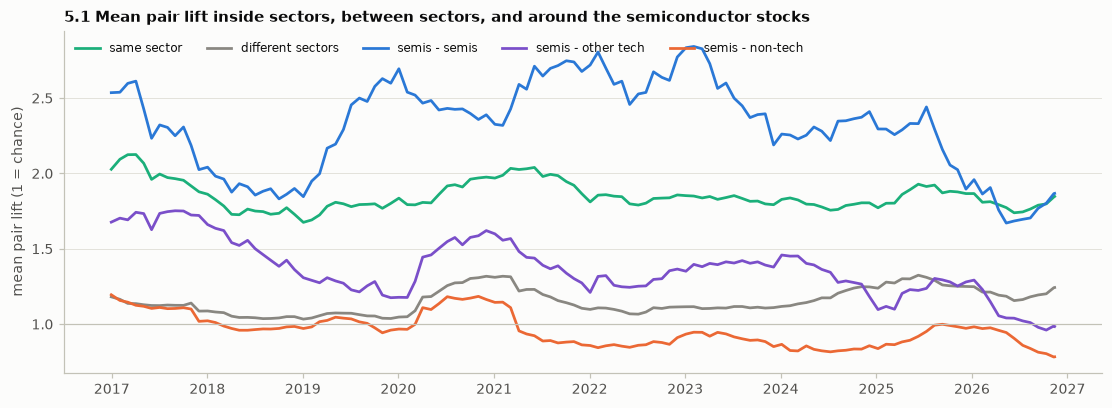

,same sector,different sectors,semis - semis,semis - other tech,semis - non-tech
2016-12-30,2.03,1.18,2.54,1.68,1.19
2022-12-02,1.86,1.11,2.77,1.37,0.91
2026-11-13,1.85,1.24,1.87,0.98,0.78


In [13]:
def pair_lift_matrix(basket, tickers=TICKERS):
    # For every pair of stocks: lift of "both made a major move in the same direction on the same day".
    up = basket[[f"{t}_UP" for t in tickers]].to_numpy(dtype=float)
    down = basket[[f"{t}_DOWN" for t in tickers]].to_numpy(dtype=float)
    together = (up.T @ up + down.T @ down) / len(basket)          # share of days both moved the same way
    by_chance = np.outer(up.mean(0), up.mean(0)) + np.outer(down.mean(0), down.mean(0))
    lift = np.divide(together, by_chance, out=np.full_like(together, np.nan), where=by_chance > 0)
    np.fill_diagonal(lift, np.nan)
    return lift


sector_arr = np.array([GROUP_OF[t] for t in TICKERS])
same_sector = sector_arr[:, None] == sector_arr[None, :]
semi_idx = [TICKERS.index(t) for t in SEMIS]
is_semi = np.isin(TICKERS, SEMIS)
it_non_semi = (sector_arr == "Information Technology") & ~is_semi
lift_by_window = {d: pair_lift_matrix(items.iloc[DAYS.get_loc(d) - WINDOW + 1:DAYS.get_loc(d) + 1]) for d in END_DATES}


def structure_summary(L):
    off = ~np.eye(len(L), dtype=bool)
    return {"same sector": np.nanmean(L[same_sector & off]), "different sectors": np.nanmean(L[~same_sector]),
            "semis - semis": np.nanmean(L[np.ix_(is_semi, is_semi)][~np.eye(is_semi.sum(), dtype=bool)]),
            "semis - other tech": np.nanmean(L[np.ix_(is_semi, it_non_semi)]),
            "semis - non-tech": np.nanmean(L[np.ix_(is_semi, sector_arr != "Information Technology")])}


structure = pd.DataFrame({d: structure_summary(L) for d, L in lift_by_window.items()}).T
structure.to_csv(OUT_DIR / "structure_over_time.csv")
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
for col, c in zip(structure.columns, ["#1baf7a", MUTED, "#2a78d6", "#7a4fc9", "#eb6834"]):
    ax.plot(structure.index, structure[col], color=c, label=col)
ax.axhline(1, color=AXIS, lw=0.8)
ax.set_ylabel("mean pair lift (1 = chance)")
ax.grid(axis="y")
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper left")
year_axis(ax)
ax.set_title("5.1 Mean pair lift inside sectors, between sectors, and around the semiconductor stocks")
save(fig, "5_1_structure_over_time")
plt.show()
KEY["structure_snapshot"] = structure.iloc[[0, structure.index.get_indexer([SPLIT], method="nearest")[0], -1]].round(2).to_dict(orient="index")
structure.iloc[[0, structure.index.get_indexer([SPLIT], method="nearest")[0], -1]].round(2)

**5.2 Which stocks trade with the semiconductor stocks?** A stock's **semiconductor affinity** is its mean pair
lift with the semiconductor stocks (excluding itself). Finance research calls a group that trades together for
reasons beyond its businesses *category-based co-movement* (Barberis, Shleifer and Wurgler, 2005). We compare the
two years before December 2022 with the latest two years. A **block bootstrap** (10-day blocks, 500 resamples)
gives a 95% interval for each change, and Benjamini-Hochberg control across stocks decides which changes are bigger
than noise.

In [14]:
def block_bootstrap(basket, rng, block=10):
    # Resample whole blocks of consecutive days, with replacement, to the original length.
    n = len(basket)
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    rows = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
    return basket.iloc[rows]


def semi_affinity(basket):
    return np.nanmean(pair_lift_matrix(basket)[:, semi_idx], axis=1)


split_pos = DAYS.get_loc(DAYS[DAYS.searchsorted(SPLIT)])
PERIODS = {"before (2 years to Nov 2022)": items.iloc[split_pos - 504:split_pos],
           "latest (2 years to Nov 2026)": items.iloc[-504:]}
N_BOOT = 500
rng = np.random.default_rng(SEED)
boot = {name: np.array([semi_affinity(block_bootstrap(b, rng)) for _ in range(N_BOOT)]) for name, b in PERIODS.items()}
point = {name: semi_affinity(b) for name, b in PERIODS.items()}
names = list(PERIODS)
diff_boot = boot[names[1]] - boot[names[0]]
change = pd.DataFrame({
    "sector": [GROUP_OF[t] for t in TICKERS], "semiconductor": is_semi,
    "before": point[names[0]], "latest": point[names[1]], "change": point[names[1]] - point[names[0]],
    "ci_low": np.nanpercentile(diff_boot, 2.5, axis=0), "ci_high": np.nanpercentile(diff_boot, 97.5, axis=0),
}, index=TICKERS)
change["p_boot"] = np.minimum(1, 2 * np.minimum((diff_boot <= 0).mean(0), (diff_boot >= 0).mean(0)))
change = change[np.isfinite(change["change"])]          # stocks without history in both periods are left out
change["significant"] = benjamini_hochberg(change["p_boot"], FDR_Q)
change = change.sort_values("change")
change.to_csv(OUT_DIR / "semi_affinity_change.csv")
KEY["semi_affinity_change"] = {
    "risers": change[change["significant"] & (change["change"] > 0)].index.tolist()[::-1],
    "fallers": change[change["significant"] & (change["change"] < 0)].index.tolist(),
    "table": change[["sector", "before", "latest", "change", "ci_low", "ci_high", "significant"]].round(2).to_dict(orient="index"),
}
print("Joined the semiconductor cluster:", KEY["semi_affinity_change"]["risers"])
print("Left it:", KEY["semi_affinity_change"]["fallers"])

Joined the semiconductor cluster: ['ORCL', 'CAT', 'MRK']
Left it: ['TXN', 'ADBE', 'NVDA', 'QCOM', 'NOW', 'AVGO', 'INTU', 'NFLX', 'MU', 'AAPL', 'AMAT', 'BKNG', 'GOOGL', 'MA', 'V', 'MSFT', 'PANW']


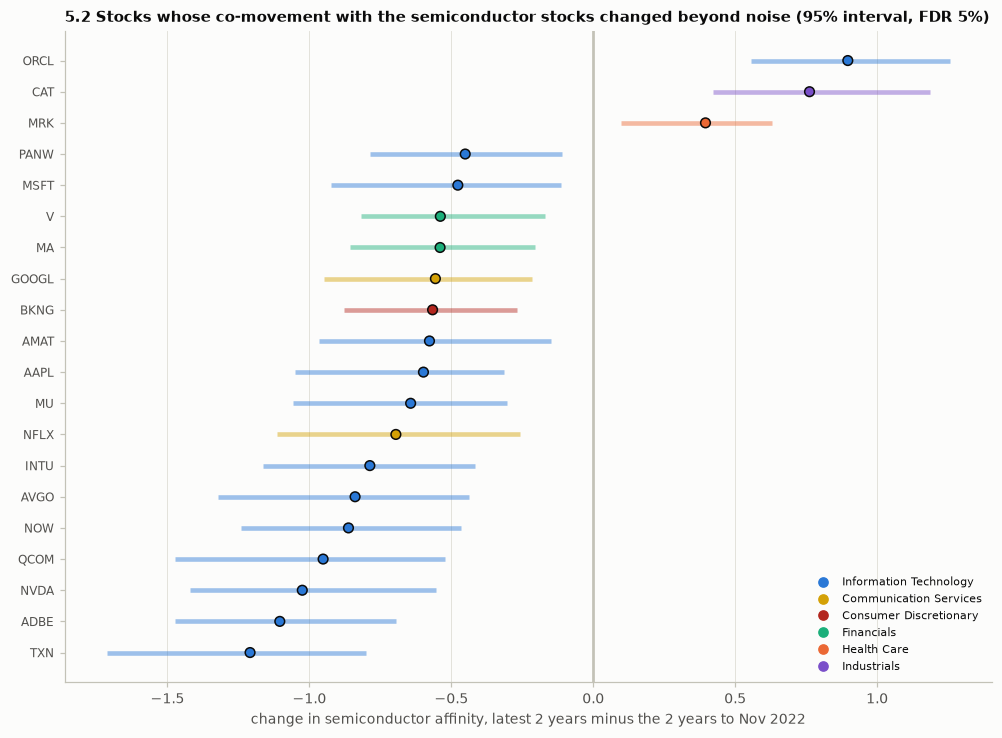

In [15]:
show = change[change["significant"]]
fig, ax = plt.subplots(figsize=(9, max(2.5, 0.28 * len(show) + 1)), layout="constrained")
y = np.arange(len(show))
cols = [SECTOR_COLORS[s] for s in show["sector"]]
ax.hlines(y, show["ci_low"], show["ci_high"], color=cols, lw=3, alpha=0.45)
ax.scatter(show["change"], y, color=cols, s=40, zorder=3, edgecolor=INK)
ax.axvline(0, color=AXIS)
ax.set_yticks(y, show.index, fontsize=8)
ax.set_xlabel("change in semiconductor affinity, latest 2 years minus the 2 years to Nov 2022")
handles = [plt.Line2D([], [], marker="o", ls="", color=SECTOR_COLORS[s], label=s) for s in show["sector"].unique()]
ax.legend(handles=handles, frameon=False, fontsize=7, loc="lower right")
ax.grid(axis="x")
ax.set_title("5.2 Stocks whose co-movement with the semiconductor stocks changed beyond noise (95% interval, FDR 5%)")
save(fig, "5_2_semi_affinity_change")
plt.show()

## 6. Which co-movement rules last? (prediction in service of the patterns)

A portfolio manager who uses a mined rule, for example "when AMAT jumps, LRCX jumps too", to judge diversification needs to know whether it will still hold next month. Section 5 shows the rule sets change. Here we ask **what makes a rule durable**.

**Target.** A rule mined from the window ending on day *t* *survives* if it is mined again, with the same thresholds, from the next 126 baskets (days *t*+1 to *t*+126). Those future days never overlap the window the rule came from.

**Features (all known on day *t*).**

| Feature | Meaning |
|---|---|
| `support`, `confidence`, `lift`, `leverage`, `conviction` | the rule's strength in its window |
| `neg_log10_p` | Fisher test strength (Section 4.3) |
| `n_items`, `n_groups`, `has_ai`, `dir_*` | what kind of stocks and moves the rule links (`n_groups` = number of GICS sectors its stocks come from; `has_ai` = it includes a semiconductor stock) |
| `age` | in how many consecutive earlier windows (21 days apart) the same rule was already found |
| `seen_last_12` | in how many of the last 12 windows it was found |
| `recent_share` | share of the rule's joint days that fell in the window's last quarter (0.25 if spread evenly) |
| `burstiness` | largest share of its joint days inside any 21-day block: high = the rule comes from one episode |
| `shock_share` | share of its joint days that were "shock days" (basket size in the top 5% of the previous year) |
| `spy_vol`, `spy_vol_recent`, `items_per_day` | the market regime of the window |

**Split by time, not at random.** Train on windows whose 126 future days end before 1 Dec 2022; test on windows that end on or after it (about the last four years). Nothing from the test period is used in training.

**Models and baselines.** Logistic regression (readable coefficients), random forest and histogram gradient boosting, against one-feature baselines that rank rules by lift, support, confidence or age.

In [16]:
def joint_days(basket_np, col_of, rule_items):
    # True on the days when every item of the rule is in the basket.
    return basket_np[:, [col_of[i] for i in rule_items]].all(axis=1)


def future_holds(future_np, col_of, antecedents, consequents):
    # Is the rule mined again from the future baskets with the same thresholds?
    a = future_np[:, [col_of[i] for i in antecedents]].all(axis=1)
    c = future_np[:, [col_of[i] for i in consequents]].all(axis=1)
    sup_a, sup_c, sup_ac = a.mean(), c.mean(), (a & c).mean()
    conf = sup_ac / sup_a if sup_a > 0 else 0.0
    lift = conf / sup_c if sup_c > 0 else 0.0
    return (sup_ac >= MIN_SUPPORT) and (conf >= MIN_CONFIDENCE) and (lift >= MIN_LIFT)


basket_size = items.sum(axis=1)
shock_cut = basket_size.rolling(WINDOW).quantile(0.95).shift(1)        # past-only threshold
shock_day = (basket_size > shock_cut).to_numpy()
items_np = items.to_numpy(dtype=bool)
COL_OF = {c: i for i, c in enumerate(items.columns)}
spy_recent = market_returns.loc[STUDY_START:].rolling(STEP).std() * np.sqrt(252)

rule_sets = {d: set(r["rule"]) if len(r) else set() for d, r in rules_by_window.items()}
ordered_dates = list(rules_by_window)
records = []
for k, d in enumerate(ordered_dates):
    rules = rules_by_window[d]
    if rules.empty:
        continue
    end = DAYS.get_loc(d)
    window_np = items_np[end - WINDOW + 1:end + 1]
    window_shock = shock_day[end - WINDOW + 1:end + 1]
    has_future = end + FUTURE_DAYS < len(items)
    future_np = items_np[end + 1:end + 1 + FUTURE_DAYS] if has_future else None
    for _, r in rules.iterrows():
        age = 0
        while k - age - 1 >= 0 and r["rule"] in rule_sets[ordered_dates[k - age - 1]]:
            age += 1
        seen = sum(r["rule"] in rule_sets[ordered_dates[j]] for j in range(max(0, k - 12), k))
        days_on = joint_days(window_np, COL_OF, r["antecedents"] | r["consequents"])
        n_on = days_on.sum()
        blocks = days_on[: (WINDOW // STEP) * STEP].reshape(-1, STEP).sum(axis=1)
        records.append({
            "window_end": d, "rule": r["rule"],
            "support": r["support"], "confidence": r["confidence"], "lift": r["lift"],
            "leverage": r["leverage"], "conviction": min(r["conviction"], 10),
            "neg_log10_p": -np.log10(max(r["p_value"], 1e-300)),
            "n_items": r["n_items"], "cross_group": int(r["cross_group"]), "n_groups": r["n_groups"],
            "has_ai": int(r["has_ai"]),
            "dir_up": int(r["direction"] == "UP"), "dir_down": int(r["direction"] == "DOWN"),
            "age": age, "seen_last_12": seen,
            "recent_share": days_on[-63:].sum() / n_on, "burstiness": blocks.max() / n_on,
            "shock_share": (days_on & window_shock).sum() / n_on,
            "spy_vol": spy_vol.loc[d], "spy_vol_recent": spy_recent.loc[d], "items_per_day": basket_size.iloc[end - WINDOW + 1:end + 1].mean(),
            "survived": (int(future_holds(future_np, COL_OF, r["antecedents"], r["consequents"])) if has_future else np.nan),
        })
# Fixed row order: mlxtend returns itemsets in an order that can change between Python sessions, and the
# random forest's bootstrap samples depend on row order. Sorting makes every run give the same numbers.
survival = pd.DataFrame(records).sort_values(["window_end", "rule"]).reset_index(drop=True)
FEATURES = ["support", "confidence", "lift", "leverage", "conviction", "neg_log10_p", "n_items",
            "n_groups", "has_ai", "dir_up", "dir_down", "age", "seen_last_12",
            "recent_share", "burstiness", "shock_share", "spy_vol", "spy_vol_recent", "items_per_day"]
labelled = survival.dropna(subset=["survived"]).copy()
labelled["survived"] = labelled["survived"].astype(int)
future_end = {d: DAYS[min(DAYS.get_loc(d) + FUTURE_DAYS, len(DAYS) - 1)] for d in labelled["window_end"].unique()}
labelled["future_end"] = labelled["window_end"].map(future_end)
train = labelled[labelled["future_end"] < SPLIT]
test = labelled[labelled["window_end"] >= SPLIT]
survival.to_csv(OUT_DIR / "rule_survival_dataset.csv", index=False)
KEY["survival_data"] = {"rules_total": len(survival), "labelled": len(labelled), "train": len(train), "test": len(test),
                        "base_rate_train": round(train["survived"].mean(), 3), "base_rate_test": round(test["survived"].mean(), 3),
                        "unique_rules": int(survival["rule"].nunique())}
print(KEY["survival_data"])

{'rules_total': 131594, 'labelled': 118241, 'train': 81643, 'test': 29256, 'base_rate_train': np.float64(0.245), 'base_rate_test': np.float64(0.276), 'unique_rules': 17992}


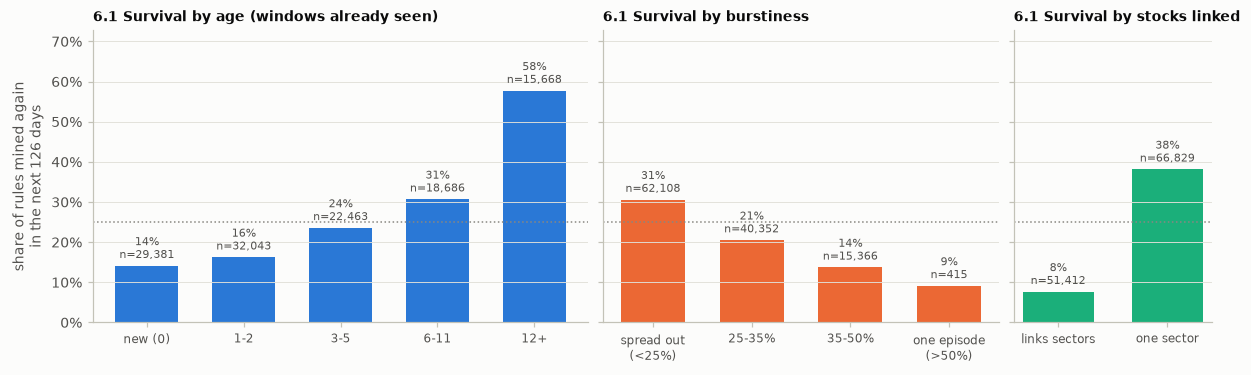

In [17]:
# 6.1 Descriptive view first: survival rate by age and by burstiness (all labelled rules).
def rate_by_bins(df, col, bins, labels):
    b = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    return df.groupby(b, observed=False)["survived"].agg(["mean", "size"])


by_age = rate_by_bins(labelled, "age", [-0.5, 0.5, 2.5, 5.5, 11.5, 1000], ["new (0)", "1-2", "3-5", "6-11", "12+"])
by_burst = rate_by_bins(labelled, "burstiness", [0, 0.25, 0.35, 0.5, 1.0], ["spread out\n(<25%)", "25-35%", "35-50%", "one episode\n(>50%)"])
by_kind = labelled.groupby(np.where(labelled["cross_group"] == 1, "links sectors", "one sector"))["survived"].agg(["mean", "size"])
KEY["survival_descriptive"] = {"by_age": by_age.round(3).to_dict(orient="index"), "by_burstiness": by_burst.round(3).to_dict(orient="index"),
                               "by_group_link": by_kind.round(3).to_dict(orient="index")}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True, layout="constrained", gridspec_kw={"width_ratios": [5, 4, 2]})
for ax, table, title, c in [(axes[0], by_age, "by age (windows already seen)", "#2a78d6"),
                            (axes[1], by_burst, "by burstiness", "#eb6834"), (axes[2], by_kind, "by stocks linked", "#1baf7a")]:
    bars = ax.bar(range(len(table)), table["mean"], color=c, width=0.65)
    ax.set_xticks(range(len(table)), table.index, fontsize=8)
    for i, (m, n) in enumerate(zip(table["mean"], table["size"])):
        ax.text(i, m + 0.01, f"{m:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=7, color=INK_SOFT)
    ax.axhline(labelled["survived"].mean(), color=MUTED, ls=":", lw=1)
    ax.set_title(f"6.1 Survival {title}", fontsize=9)
    ax.grid(axis="y")
axes[0].set_ylabel("share of rules mined again\nin the next 126 days")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylim(0, max(by_age["mean"].max(), by_burst["mean"].max()) + 0.15)
save(fig, "6_1_survival_by_feature")
plt.show()

In [18]:
# 6.2 Models against one-feature baselines, trained on windows before Dec 2022 and tested on later ones.
def precision_at(y, score, top=0.2):
    # Precision among the top 20% of rules by score: "if we only trusted these, how many would hold?"
    k = max(1, int(len(y) * top))
    return float(np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean())


def evaluate(y, score):
    return {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score), "precision@20%": precision_at(y, score)}


MODELS = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED),
}
results, fitted = {}, {}
for name, model in MODELS.items():
    model.fit(train[FEATURES], train["survived"])
    prob = model.predict_proba(test[FEATURES])[:, 1]
    fitted[name] = model
    results[name] = evaluate(test["survived"], prob) | {"Brier": brier_score_loss(test["survived"], prob)}
for col in ["lift", "support", "confidence", "age"]:
    results[f"baseline: rank by {col}"] = evaluate(test["survived"], test[col] + 1e-9 * test["support"])
results["baseline: all rules survive"] = {"ROC-AUC": 0.5, "PR-AUC": test["survived"].mean(), "precision@20%": test["survived"].mean()}
results = pd.DataFrame(results).T
results.to_csv(OUT_DIR / "survival_model_results.csv")
KEY["survival_models"] = results.round(3).to_dict(orient="index")
results.round(3)

,ROC-AUC,PR-AUC,precision@20%,Brier
logistic regression,0.790,0.627,0.642,0.154
random forest,0.794,0.640,0.648,0.151
gradient boosting,0.799,0.646,0.659,0.149
baseline: rank by lift,0.520,0.269,0.229,NaN
baseline: rank by support,0.693,0.503,0.542,NaN
baseline: rank by confidence,0.506,0.260,0.184,NaN
baseline: rank by age,0.703,0.559,0.585,NaN
baseline: all rules survive,0.500,0.276,0.276,NaN


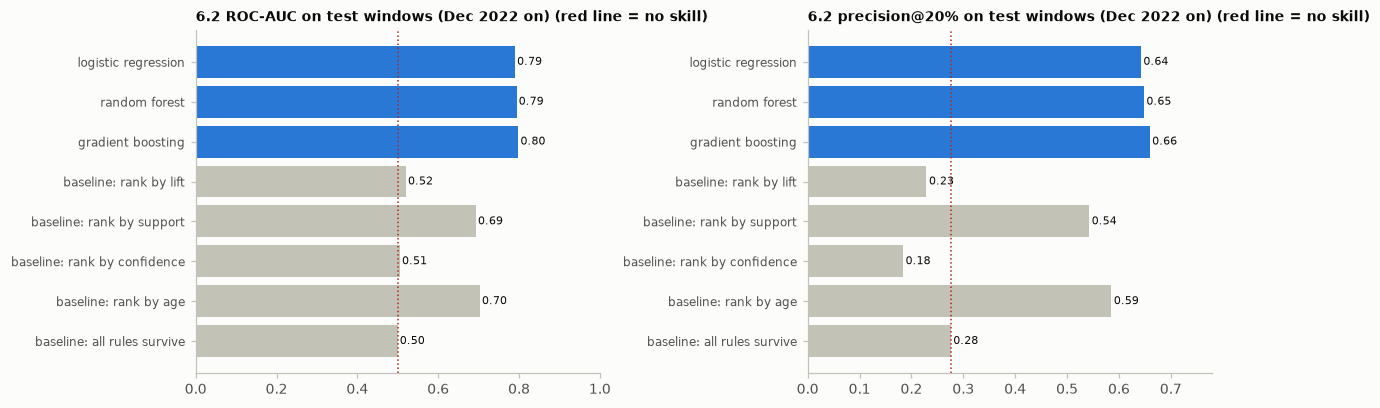

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
order = results.index.tolist()
colors_ = ["#2a78d6" if not n.startswith("baseline") else AXIS for n in order]
for ax, metric in zip(axes, ["ROC-AUC", "precision@20%"]):
    ax.barh(range(len(order))[::-1], results[metric], color=colors_)
    ax.set_yticks(range(len(order))[::-1], order, fontsize=8)
    for i, v in zip(range(len(order))[::-1], results[metric]):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=7.5)
    ax.set_xlim(0, max(1, results[metric].max() + 0.1) if metric == "ROC-AUC" else results[metric].max() + 0.12)
    ref = 0.5 if metric == "ROC-AUC" else test["survived"].mean()
    ax.axvline(ref, color=HIGHLIGHT, ls=":", lw=1)
    ax.set_title(f"6.2 {metric} on test windows (Dec 2022 on) (red line = no skill)", fontsize=9)
save(fig, "6_2_survival_models")
plt.show()

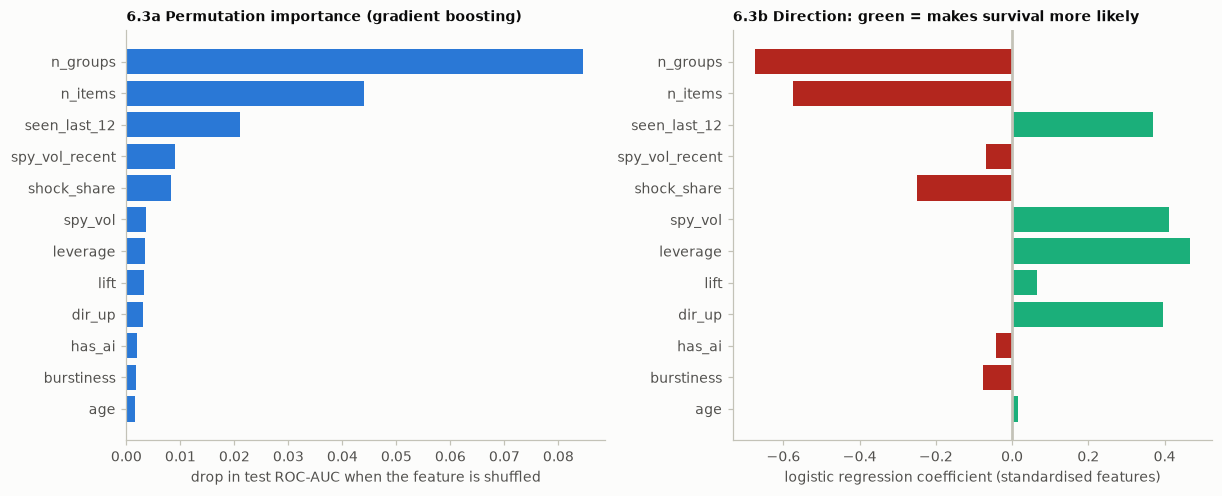

In [20]:
# 6.3 What makes a rule last? Permutation importance on the test set, plus the logistic regression's signs.
best_name = results.loc[list(MODELS), "ROC-AUC"].idxmax()
imp = permutation_importance(fitted[best_name], test[FEATURES], test["survived"], scoring="roc_auc",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
coef = pd.Series(fitted["logistic regression"][-1].coef_[0], index=FEATURES)
KEY["survival_importance"] = {"model": best_name, "top": importance.sort_values(ascending=False).head(8).round(4).to_dict(),
                              "logit_coef": coef.round(3).to_dict()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
top_imp = importance.tail(12)
axes[0].barh(top_imp.index, top_imp.values, color="#2a78d6")
axes[0].set_xlabel("drop in test ROC-AUC when the feature is shuffled")
axes[0].set_title(f"6.3a Permutation importance ({best_name})", fontsize=9)
c_sorted = coef.reindex(top_imp.index)
axes[1].barh(c_sorted.index, c_sorted.values, color=[("#1baf7a" if v > 0 else "#b3261e") for v in c_sorted.values])
axes[1].axvline(0, color=AXIS)
axes[1].set_xlabel("logistic regression coefficient (standardised features)")
axes[1].set_title("6.3b Direction: green = makes survival more likely", fontsize=9)
save(fig, "6_3_survival_importance")
plt.show()

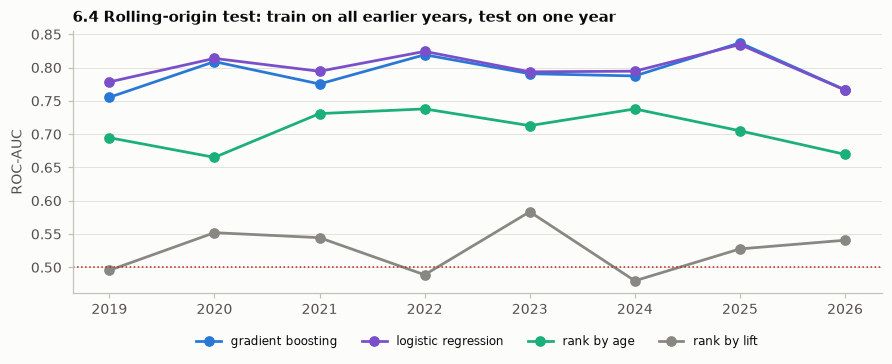

,test rules,survival rate,gradient boosting,logistic regression,rank by lift,rank by age
year,,,,,,
2019,7944,0.273,0.755,0.779,0.495,0.695
2020,13934,0.247,0.809,0.814,0.552,0.665
2021,24740,0.287,0.775,0.795,0.545,0.731
2022,18196,0.158,0.819,0.824,0.489,0.738
2023,5281,0.306,0.791,0.794,0.583,0.713
2024,8179,0.287,0.788,0.795,0.480,0.738
2025,10882,0.205,0.837,0.835,0.528,0.705
2026,3992,0.428,0.767,0.766,0.541,0.670


In [21]:
# 6.4 Rolling-origin check: retrain each year on everything known before it, test on that year's windows.
roll = []
for year in range(2019, 2027):
    start_y = pd.Timestamp(f"{year}-01-01")
    tr = labelled[labelled["future_end"] < start_y]
    te = labelled[(labelled["window_end"] >= start_y) & (labelled["window_end"] < pd.Timestamp(f"{year + 1}-01-01"))]
    if len(te) < 50 or te["survived"].nunique() < 2:
        continue
    m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED).fit(tr[FEATURES], tr["survived"])
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(tr[FEATURES], tr["survived"])
    roll.append({"year": year, "test rules": len(te), "survival rate": te["survived"].mean(),
                 "gradient boosting": roc_auc_score(te["survived"], m.predict_proba(te[FEATURES])[:, 1]),
                 "logistic regression": roc_auc_score(te["survived"], lr.predict_proba(te[FEATURES])[:, 1]),
                 "rank by lift": roc_auc_score(te["survived"], te["lift"]),
                 "rank by age": roc_auc_score(te["survived"], te["age"] + 1e-9 * te["support"])})
roll = pd.DataFrame(roll).set_index("year")
roll.to_csv(OUT_DIR / "survival_rolling_origin.csv")
KEY["survival_rolling"] = roll.round(3).to_dict(orient="index")

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
for col, c in zip(["gradient boosting", "logistic regression", "rank by age", "rank by lift"], ["#2a78d6", "#7a4fc9", "#1baf7a", MUTED]):
    ax.plot(roll.index, roll[col], marker="o", color=c, label=col)
ax.axhline(0.5, color=HIGHLIGHT, ls=":", lw=1)
ax.set_ylabel("ROC-AUC")
ax.set_xticks(roll.index)
ax.grid(axis="y")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("6.4 Rolling-origin test: train on all earlier years, test on one year")
save(fig, "6_4_survival_rolling_origin")
plt.show()
roll.round(3)

In [22]:
# 6.5 The actionable output: rules in the latest window, scored by the model trained on every labelled rule.
final_model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=SEED)
final_model.fit(labelled[FEATURES], labelled["survived"])
latest = survival[survival["window_end"] == END_DATES[-1]].copy()
latest["p_survive"] = final_model.predict_proba(latest[FEATURES])[:, 1]
cols = ["rule", "lift", "confidence", "age", "burstiness", "p_survive"]
# Ties in p_survive are broken by the rule text, so the tables are the same on every run.
durable = latest.sort_values(["p_survive", "rule"], ascending=[False, True])[cols].head(10)
fragile = latest[latest["lift"] >= latest["lift"].quantile(0.75)].sort_values(["p_survive", "rule"])[cols].head(10)
durable.to_csv(OUT_DIR / "latest_durable_rules.csv", index=False)
fragile.to_csv(OUT_DIR / "latest_fragile_rules.csv", index=False)
KEY["latest_rules"] = {"window_end": str(END_DATES[-1].date()), "n_rules": len(latest),
                       "durable": durable.round(3).to_dict(orient="records"), "fragile": fragile.round(3).to_dict(orient="records")}
print(f"Most durable rules in the window ending {END_DATES[-1].date()}:")
durable.round(2)

Most durable rules in the window ending 2026-11-13:


,rule,lift,confidence,age,burstiness,p_survive
129958,CVX_DOWN -> COP_DOWN,6.82,0.89,114,0.16,0.99
130749,LRCX_DOWN -> AMAT_DOWN,5.21,0.70,113,0.19,0.99
129186,AMAT_DOWN -> LRCX_DOWN,5.21,0.76,113,0.19,0.99
130785,LRCX_UP -> AMAT_UP,4.15,0.71,112,0.21,0.98
129254,AMAT_UP -> LRCX_UP,4.15,0.79,102,0.21,0.98
131541,V_DOWN -> MA_DOWN,5.40,0.75,114,0.19,0.98
130809,MA_DOWN -> V_DOWN,5.40,0.60,114,0.19,0.97
129960,CVX_DOWN -> XOM_DOWN,6.30,0.75,114,0.19,0.97
129805,COP_DOWN -> CVX_DOWN,6.82,0.76,81,0.16,0.97
131398,SO_DOWN -> DUK_DOWN,5.09,0.83,119,0.14,0.96


In [23]:
print("Strong-looking rules (top 25% lift) the model expects to fade:")
fragile.round(2)

Strong-looking rules (top 25% lift) the model expects to fade:


,rule,lift,confidence,age,burstiness,p_survive
129151,"ADBE_UP, MA_UP -> CAT_DOWN",5.41,0.69,1,0.27,0.00
129117,"ADBE_UP, BRK-B_UP -> CAT_DOWN",5.78,0.73,1,0.27,0.00
129658,"BRK-B_UP, CAT_DOWN -> ADBE_UP",6.24,0.92,1,0.27,0.00
129726,"CAT_DOWN, MA_UP -> AMAT_DOWN",5.93,0.80,1,0.25,0.01
129250,"AMAT_DOWN, V_UP -> CAT_DOWN",6.19,0.79,1,0.27,0.01
129734,"CAT_DOWN, V_UP -> AMAT_DOWN",5.82,0.79,1,0.27,0.01
129236,"AMAT_DOWN, MA_UP -> CAT_DOWN",7.27,0.92,1,0.25,0.01
130667,"LIN_UP, PG_UP -> DUK_UP",5.33,0.85,1,0.18,0.01
129760,"CMCSA_UP, DUK_UP -> PG_UP",5.37,0.92,1,0.36,0.01
131341,"PG_UP, USB_UP -> MCD_UP",5.25,0.69,1,0.27,0.01


## 7. Unusual days: anomaly detection on daily baskets

An **Isolation Forest** finds unusual days without being told about any news. It builds random trees that split the
days on random stocks' z-scores; a day that is isolated after only a few splits is unusual. Unlike simply counting
big moves, it also flags odd *combinations* (for example banks up while consumer staples fall). The top 1% of days
are the "unusual days" that `events.ipynb` compares with the event calendar.

In [24]:
Z = zscores.clip(-10, 10).fillna(0)
forest = IsolationForest(n_estimators=300, contamination=0.01, random_state=SEED).fit(Z)
anomaly = pd.Series(-forest.score_samples(Z), index=Z.index, name="anomaly score")   # higher = more unusual
size = items.sum(axis=1)
n_top = int(round(0.01 * len(anomaly)))
top_if = set(anomaly.nlargest(n_top).index)
top_size = set(size.nlargest(n_top).index)
agreement = len(top_if & top_size) / len(top_if | top_size)


def describe_day(day, n=6):
    z = Z.loc[day]
    movers = z.abs().sort_values(ascending=False).head(n).index
    return ", ".join(f"{t} {z[t]:+.1f}" for t in movers)


top = anomaly.nlargest(n_top)
top_days = pd.DataFrame({"anomaly score": top.round(3), "items in basket": size.loc[top.index],
                         "largest residual moves (z)": [describe_day(d) for d in top.index]})
top_days.index.name = "Date"
top_days.to_csv(OUT_DIR / "top_anomalous_days.csv")
anomaly.to_csv(OUT_DIR / "anomaly_scores.csv")
KEY["anomaly"] = {"n_top_days": n_top, "jaccard_if_vs_basket_size_top1pct": round(agreement, 3),
                  "top_days": {str(k.date()): v for k, v in top_days["largest residual moves (z)"].items()}}
print(f"{n_top} unusual days. Overlap with the {n_top} largest baskets (Jaccard): {agreement:.2f}")
top_days

27 unusual days. Overlap with the 27 largest baskets (Jaccard): 0.74


,anomaly score,items in basket,largest residual moves (z)
Date,,,
2020-11-09,0.613,68,"BKNG +10.0, AXP +10.0, LOW -8.6, MA +8.1, COST..."
2020-03-19,0.596,74,"AVGO +7.9, KO -5.9, SBUX +5.5, ACN +5.3, FDX +..."
2016-11-10,0.580,74,"PEP -6.6, BRK-B +6.4, WFC +6.4, GOOGL -5.6, JP..."
2026-11-04,0.573,75,"CVS -7.6, MMM +5.8, MCD +4.9, BRK-B +4.6, GEV ..."
2020-03-18,0.571,72,"CVX -10.0, CSCO +7.0, FDX +6.5, GM -6.1, ANET ..."
2016-11-09,0.568,75,"PFE +10.0, GD +8.8, AMT -7.0, CAT +6.9, LLY +6..."
2024-11-06,0.557,65,"GS +8.9, JPM +8.2, COF +7.7, MS +7.2, WFC +6.8..."
2025-04-04,0.556,70,"RTX -5.8, T -4.7, V -4.5, ABBV -4.5, PG -4.3, ..."
2020-03-13,0.555,72,"ORCL +9.8, ADBE +9.0, AXP +8.5, GS +8.1, JPM +..."


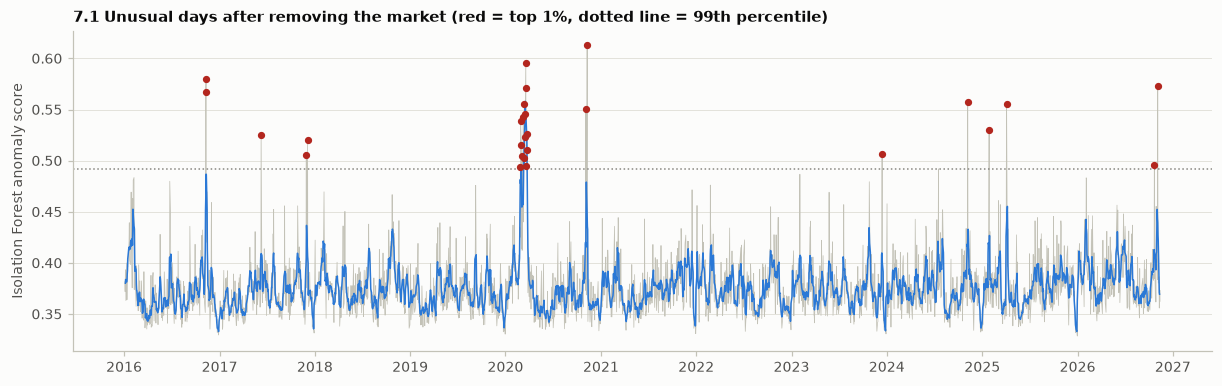

In [25]:
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
smooth = anomaly.rolling(5, center=True).mean()
ax.plot(anomaly.index, anomaly, color=AXIS, lw=0.5)
ax.plot(smooth.index, smooth, color=MODE_COLORS["residual"], lw=1)
ax.axhline(anomaly.quantile(0.99), color=MUTED, ls=":", lw=1)
ax.scatter(top.index, top, color=HIGHLIGHT, s=14, zorder=5)
ax.set_ylabel("Isolation Forest anomaly score")
ax.grid(axis="y")
year_axis(ax)
ax.set_title("7.1 Unusual days after removing the market (red = top 1%, dotted line = 99th percentile)")
save(fig, "7_1_anomaly_timeline")
plt.show()

## 8. Key numbers

Every number used in the slides is written to `outputs/rules/key_numbers.json`.

In [26]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


KEY["settings"] = {"MAIN_MODE": MAIN_MODE, "Z_K": Z_K, "VOL_WINDOW": VOL_WINDOW, "BETA_WINDOW": BETA_WINDOW, "WINDOW": WINDOW,
                   "STEP": STEP, "MIN_SUPPORT": MIN_SUPPORT, "MIN_CONFIDENCE": MIN_CONFIDENCE, "MIN_LIFT": MIN_LIFT,
                   "MAX_LEN": MAX_LEN, "FUTURE_DAYS": FUTURE_DAYS, "SPLIT": str(SPLIT.date()), "SEED": SEED}
with open(OUT_DIR / "key_numbers.json", "w") as f:
    json.dump(to_jsonable(KEY), f, indent=1)
print(json.dumps(to_jsonable({k: KEY[k] for k in ["rolling", "chance", "survival_data", "anomaly"] if k in KEY}), indent=1)[:3000])

{
 "rolling": {
  "n_windows": 120,
  "pair_rules_median": {
   "excess": 779.0,
   "raw": 2461.0,
   "residual": 421.0
  },
  "pair_rules_max": {
   "excess": 2085,
   "raw": 11842,
   "residual": 945
  },
  "spearman_rules_vs_spy_vol": {
   "excess": 0.49,
   "raw": 0.74,
   "residual": 0.42
  },
  "main_rules_median": 899.0,
  "main_rules_max": 3101
 },
 "chance": {
  "n_possible_rules": 7801200,
  "real_rules_total": 131594,
  "shuffled_rules_total": 337.3,
  "chance_ratio_overall": 0.0026,
  "significant_share": 0.765
 },
 "survival_data": {
  "rules_total": 131594,
  "labelled": 118241,
  "train": 81643,
  "test": 29256,
  "base_rate_train": 0.245,
  "base_rate_test": 0.276,
  "unique_rules": 17992
 },
 "anomaly": {
  "n_top_days": 27,
  "jaccard_if_vs_basket_size_top1pct": 0.742,
  "top_days": {
   "2020-11-09": "BKNG +10.0, AXP +10.0, LOW -8.6, MA +8.1, COST -7.9, DIS +7.9",
   "2020-03-19": "AVGO +7.9, KO -5.9, SBUX +5.5, ACN +5.3, FDX +5.2, MDT +5.2",
   "2016-11-10": "PEP -6